# Un inicio dado por una red para hologramas de volumen: ¿una fase aprendida supera al lazo GS en tres planos?

**Pregunta:** ¿Puede una red que aprendió la física dar un holograma mejor para un objetivo de tres planos que el lazo volumétrico de Gerchberg-Saxton al mismo costo, y es mejor por la exactitud del volumen, por los números propios de las trampas o solo por uno de ellos?

- **Nivel:** 3, Comparación con métodos publicados
- **Requisitos previos:** notebooks 01 y 02 del tema 01-fourier-optics (el campo focal y las métricas de las trampas) y notebooks 01 y 02 de este tema (la entrada de la red y su entrenamiento)
- **Método ejecutado:** M17, la red multiplano publicada `cgh-net` (un modelo al estilo DeepCGH), contra el M19 clásico
- **Tiempo de lectura:** unos 50 minutos; el notebook se ejecuta en unos 90 segundos

## Objetivos

Un holograma para trampas a varias profundidades es más difícil que uno para un solo plano, porque la luz debe ser correcta en un volumen y cada plano ve la luz destinada a los otros. Construirás un objetivo de tres planos con el retículo del caso C05, ejecutarás el lazo volumétrico clásico de Gerchberg-Saxton (M19) sobre él y verás cómo se mueve su exactitud con el número de iteraciones, ejecutarás en un solo paso la red publicada del producto, leerás qué hace cada holograma en los tres planos y después pondrás a prueba la afirmación en ocho volúmenes más. Al final sabrás en qué medida gana la red, por cuánto, en cuál pierde y por qué el híbrido del producto, que entrega la fase de la red a M19, nunca conserva el refinamiento.

## Preparación

El entorno de los notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows). Los paquetes que usa este notebook, con sus versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2 onnxruntime==1.31.1
```

DinHot no publica ningún paquete propio: sus métodos viven en `data-pipeline/pipeline/` y el notebook los importa por su ruta. La red es el grafo ONNX publicado del producto, el mismo archivo que ejecuta el navegador, leído con onnxruntime. La celda siguiente importa las herramientas, imprime sus versiones y pone el pipeline en la ruta.

In [1]:
# las herramientas y sus versiones, luego los módulos del pipeline por su ruta
import importlib.metadata as md
import json
import sys
import time
import warnings
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.build import setup_of
from pipeline.io.contract import read_cases
from pipeline.model.holo.core import forward, metrics, modes
from pipeline.model.holo.core.geometry import focal_bin_m
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.traps import Trap, TrapSet
from pipeline.model.holo.core.types import Budget, Target
from pipeline.model.holo.learned import convert, evaluation, generators
from pipeline.model.holo.methods.baseline import m19_multiplane
from pipeline.model.holo.methods.learned import m17_cgh_net

for name in ("numpy", "matplotlib", "onnxruntime"):
    print(name, md.version(name))

numpy 2.4.6
matplotlib 3.11.2
onnxruntime 1.31.1


## Datos

- Propietario: este repositorio, https://github.com/fsantibanezleal/CEFOP_DinHot.
- Clase de licencia: sintética. El caso lo escribe el producto y la red se entrenó con objetivos de un generador con semilla, de modo que no rige ningún conjunto de datos de terceros y la licencia del repositorio cubre todos los archivos.
- Archivos leídos: `data/examples/cases.json` (caso C05, 51 trampas en tres planos), el grafo publicado `models/cgh-net.onnx` con su ficha `models/cgh-net.json`, y el generador de volúmenes de prueba del propio producto, que usa la segunda mitad del notebook.

El caso C05 se escribió para un SLM de 256 por 256 píxeles y la red se entrenó para 128 por 128 píxeles sin relleno. La celda siguiente conserva la óptica del caso (1064 nm, distancia focal de 2,4 mm, píxeles de 10 um) y fija la grilla a la de la red, que luego informa en bins focales y rangos de Rayleigh.

In [2]:
# caso C05, tres planos de trampas: su óptica, llevada a la grilla de 128 x 128 píxeles con que se entrenó la red
records = {rec["case_id"]: rec for rec in read_cases(ROOT / "data" / "examples" / "cases.json")}
rec = records["C05_multiplane_vortices"]
setup = replace(setup_of(rec), n_pix=128, pad=1)
bin_m, zr = focal_bin_m(setup), convert.rayleigh_range_m(setup)
print(f"longitud de onda {setup.wavelength_m * 1e9:.0f} nm, distancia focal {setup.focal_m * 1e3:.1f} mm")
print(f"un bin focal = {bin_m * 1e6:.3f} um, un rango de Rayleigh limitado por el SLM = {zr * 1e6:.2f} um")
print(f"el caso tiene {len(rec['target']['traps'])} trampas en los planos z = -10, 0 y +10 um")

longitud de onda 1064 nm, distancia focal 2.4 mm
un bin focal = 1.995 um, un rango de Rayleigh limitado por el SLM = 4.76 um
el caso tiene 51 trampas en los planos z = -10, 0 y +10 um


## Método

**El objetivo.** Un objetivo de volumen es un conjunto de vóxeles puntuales, cada uno en uno de tres planos en $z = -8$, $0$ y $+8$ rangos de Rayleigh de la apertura del SLM, $z_R = \lambda f^2 / (\pi R^2)$ con $R = N p / 2$; con esta unidad un término de lente de $Z$ rad en el borde de la apertura mueve el foco $Z$ rangos, y por eso la red no depende de la longitud de onda ni de la distancia focal. Las posiciones laterales del objetivo son bins focales enteros.

**El lazo clásico, M19.** Whyte y Courtial (2005, https://doi.org/10.1088/1367-2630/7/1/117) tratan el holograma y el volumen como un par de Fourier tridimensional. Con $K$ el campo sobre la esfera de Ewald en el volumen del espacio $k$ y $a_m$ la amplitud objetivo en el vóxel $m$, una iteración es

$$U = \mathcal{F}_{3D} K, \qquad U' = a_m e^{i \arg U}\ \text{en los vóxeles objetivo, } 0 \text{ en el resto}, \qquad \phi = \arg\big(\mathcal{F}_{3D}^{-1} U'\big)\big|_{\text{esfera}},$$

y la nueva amplitud del SLM se repone al haz de entrada. Optimiza los vóxeles que se le dan y nada más, un hecho que importa al final.

**La medida.** DeepCGH (Eybposh et al. 2020, https://doi.org/10.1364/OE.399624) puntúa un volumen con la exactitud $AC = \frac{1}{P}\sum_p 2\sum T_p I_p / (\sum T_p^2 + \sum I_p^2)$ sobre $P$ planos, con $T_p$ el objetivo e $I_p$ la intensidad del holograma en el plano $p$, ambos normalizados a suma unitaria. El producto usa esta definición para la pérdida de la red, para la línea base y para la evaluación (la fórmula propia del artículo no se leyó, de modo que es la lectura que hace el producto). $AC$ vale 1 para una copia perfecta de las imágenes objetivo, incluido su desenfoque.

**La comparación justa.** Un paso de la red cuesta menos que una iteración de M19, y el notebook lo comprueba. Así, un híbrido que gasta $k$ iteraciones después de la red cuesta menos que M19 con $k + 1$ iteraciones, y toda comparación de abajo le da a M19 la iteración extra.

El primer paso construye el objetivo. El retículo triangular de 17 trampas del caso (separadas 8 um) se redondea a bins enteros y se repite en los tres planos, lo que da 51 trampas. Los doce vórtices del caso se descartan, porque la red no admite carga.

In [3]:
# redondea la red del caso a bins enteros y lleva sus tres planos a -8, 0 y +8 rangos de Rayleigh de la red
dz = m17_cgh_net.plane_dz_m(setup)  # el paso axial del vóxel que necesita M19: la separación de los planos
plane_of = {-10.0: -1, 0.0: 0, 10.0: 1}
traps = []
for t in rec["target"]["traps"]:
    x_bin, y_bin = round(t["x_um"] * 1e-6 / bin_m), round(t["y_um"] * 1e-6 / bin_m)
    traps.append(Trap(t["id"], x_bin * bin_m, y_bin * bin_m, plane_of[t["z_um"]] * 8 * zr))
target = Target.from_traps(TrapSet(traps))
plane_index = np.rint(target.traps.z_m / (8 * zr)).astype(int)
dropped = int(np.sum([t["charge"] != 0 for t in rec["target"]["traps"]]))
print("trampas por plano (z = -8, 0, +8 zR):", np.bincount(plane_index + 1).tolist())
print("paso de la red en bins:", round(8e-6 / bin_m, 2), "| cargas de vórtice descartadas:", dropped)

trampas por plano (z = -8, 0, +8 zR): [17, 17, 17]
paso de la red en bins: 4.01 | cargas de vórtice descartadas: 12


El retículo está separado 4,01 bins, de modo que el redondeo no mueve ninguna trampa más de medio bin, hay 17 trampas en cada plano y cada trampa tiene su propio vóxel, que M19 exige. La celda siguiente le pide al producto la entrada de la red: una imagen por plano con la raíz cuadrada de una intensidad de energía unitaria, cada trampa dibujada como un punto gaussiano de un bin de ancho. La figura muestra qué se le pide producir a la red.

entrada (3, 128, 128) | energía por plano [1.0, 1.0, 1.0]


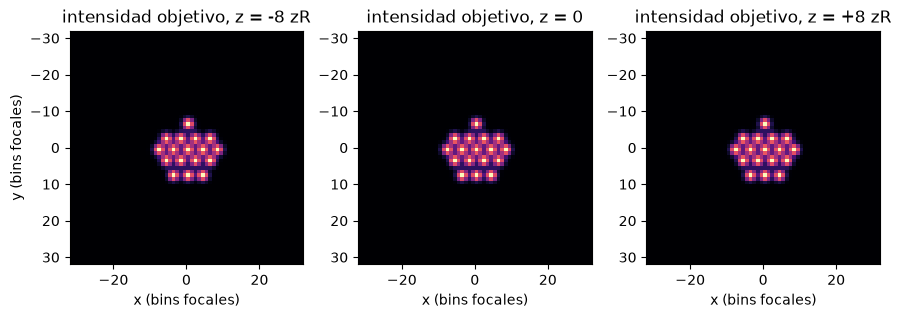

In [4]:
# la entrada de la red: una imagen de amplitud de energía unitaria por plano, dibujada como la intensidad que se le pide
DEPTHS = ("-8 zR", "0", "+8 zR")
amps = m17_cgh_net.planes_from_traps(setup, target.traps)[0]
print("entrada", amps.shape, "| energía por plano", (amps.astype(float) ** 2).sum(axis=(1, 2)).round(3).tolist())
fig, axes = plt.subplots(1, 3, figsize=(9, 3.2))
for ax, img, z in zip(axes, amps, DEPTHS):
    ax.imshow(img[32:96, 32:96] ** 2, cmap="magma", extent=(-32, 32, 32, -32))
    ax.set_title(f"intensidad objetivo, z = {z}")
    ax.set_xlabel("x (bins focales)")
axes[0].set_ylabel("y (bins focales)")
fig.tight_layout()
plt.show()

Los tres paneles son el mismo retículo, porque el caso pone las mismas 17 posiciones en cada plano; solo cambia la profundidad. Cada punto mide unos dos bins de ancho, la resolución de la grilla focal, de modo que los puntos de un retículo de 4 bins casi se tocan. Las imágenes aún no dicen nada de la luz entre los planos: un holograma que hiciera exactamente estas tres imágenes tendría igual que sobrevivir al desenfoque entre ellas, y el paso siguiente mide cómo lo resuelve el lazo clásico. Ejecuta M19 desde el inicio aleatorio del motor y guarda la fase con 1, 2, 4, 8, 16 y 30 iteraciones continuando la misma corrida, lo que da el mismo resultado que corridas separadas porque el único estado del lazo es la fase.

In [5]:
# GS volumétrico (M19) continuado desde su propia fase: la exactitud tras 1, 2, 4, 8, 16 y 30 iteraciones
marks = (1, 2, 4, 8, 16, 30)
phis, phi_now, done = {}, None, 0
for k in marks:
    res = m19_multiplane.run(setup, target, budget=Budget(k - done), rng=Rng(1), init=phi_now, dz_m=dz)
    phi_now, done = res.phi, k
    phis[k] = phi_now
ac_m19 = {k: evaluation.plane_accuracy(amps, phis[k], setup) for k in marks}
for k in marks:
    print(f"M19 con {k:2d} iteraciones AC {ac_m19[k]:.4f}")

M19 con  1 iteraciones AC 0.7220
M19 con  2 iteraciones AC 0.7244
M19 con  4 iteraciones AC 0.7245
M19 con  8 iteraciones AC 0.7290
M19 con 16 iteraciones AC 0.7423
M19 con 30 iteraciones AC 0.7417


## Comparación

El método publicado para este problema es el holograma aprendido de DeepCGH (Eybposh et al. 2020): una U-Net recibe las imágenes objetivo de todos los planos y entrega una sola fase del SLM, y se entrena sin etiquetas, haciendo de la propia exactitud $AC$ la pérdida a través de una propagación diferenciable a cada plano. El artículo la informa al menos 10 veces más rápida que Gerchberg-Saxton y de 9 a 43 por ciento más exacta en sus propios volúmenes simulados (el dossier del producto registra estas cifras desde el texto del artículo). El M17 de DinHot es ese planteamiento al tamaño de un modelo de navegador: una U-Net de 0,99 millones de parámetros en un grafo ONNX de 4,7 MB, tres planos de 128 por 128 bins de entrada, una fase de 128 por 128 de salida, entrenada 16000 pasos con volúmenes aleatorios, de retículos, de anillos y mixtos generados con semilla. Su ficha registra el entrenamiento, y un modelo que no cumpliera su criterio no se publicaría.

Un paso de la red es una llamada al método con el refinamiento desactivado. La celda primero calienta la sesión y después mide el tiempo de un paso de la red contra una iteración de M19. Los tiempos varían de una máquina a otra, de modo que solo se imprime la comparación.

In [6]:
# un paso directo de la red publicada, medido contra una iteración del GS volumétrico (el mejor de tres)
m17_cgh_net.run(setup, target, budget=Budget(1), rng=Rng(1), refine=False)  # calentamiento: carga la sesión ONNX
net = m17_cgh_net.run(setup, target, budget=Budget(1), rng=Rng(1), refine=False)
times_net, times_iter = [], []
for _ in range(3):
    t0 = time.perf_counter()
    m17_cgh_net.run(setup, target, budget=Budget(1), rng=Rng(1), refine=False)
    times_net.append(time.perf_counter() - t0)
    t0 = time.perf_counter()
    m19_multiplane.run(setup, target, budget=Budget(1), rng=Rng(1), dz_m=dz)
    times_iter.append(time.perf_counter() - t0)
t_net, t_iter = min(times_net), min(times_iter)
print("procedencia:", net.meta["provenance"], "| fase", net.phi.shape)
print(f"rango de la fase {net.phi.min():.2f} a {net.phi.max():.2f} rad")
print("un paso de la red es más barato que una iteración de M19:", t_net < t_iter)

procedencia: real | fase (128, 128)
rango de la fase -3.14 a 3.14 rad
un paso de la red es más barato que una iteración de M19: True


La procedencia dice `real`: respondió el grafo publicado, no la línea base que el catálogo promete cuando falta el modelo. La fase es un arreglo de 128 por 128 envuelto al intervalo de menos pi a pi, y un paso cuesta menos que una iteración de M19, de modo que la regla de comparación de la sección Método se cumple. La celda siguiente mide qué hace esa fase. Reenfoca el holograma a cada plano restando el término de lente del plano, aplica la FFT focal del motor y normaliza, y después puntúa cada plano con la exactitud del módulo de evaluación del propio producto.

In [7]:
# qué hace una fase en los tres planos: se reenfoca con el término de lente del plano y se aplica la FFT focal del motor
def plane_images(phi):
    images = []
    for z in (-8, 0, 8):
        field = forward.fft_focal_field(phi - modes.lens_phase(setup, z * zr), setup)
        intensity = np.abs(field) ** 2
        images.append(intensity / intensity.sum())
    return np.array(images)


per_plane = [evaluation.plane_accuracy(amps[k:k + 1], net.phi, setup, (z,)) for k, z in enumerate((-8.0, 0.0, 8.0))]
print("exactitud AC por plano:", np.round(per_plane, 4).tolist(), "| promedio", round(float(np.mean(per_plane)), 4))
ac_net = evaluation.plane_accuracy(amps, net.phi, setup)
print("exactitud del volumen con la función del propio producto:", round(ac_net, 4))

exactitud AC por plano: [0.7372, 0.7331, 0.7652] | promedio 0.7452
exactitud del volumen con la función del propio producto: 0.7452


La exactitud es 0,7372, 0,7331 y 0,7652 en los tres planos y 0,7452 en promedio, y las dos líneas del final coinciden porque la función que puntúa el volumen es la que puntúa cada plano. Un valor de 0,75 no significa que tres cuartos de las trampas estén bien: $AC$ compara imágenes completas, de modo que el desenfoque de los puntos y la luz entre ellos forman parte de la nota. Los planos externos están cerca del central, lo que dice que la red maneja el desenfoque y no solo el plano en foco. La figura siguiente pone el objetivo sobre la intensidad de la red en los tres planos.

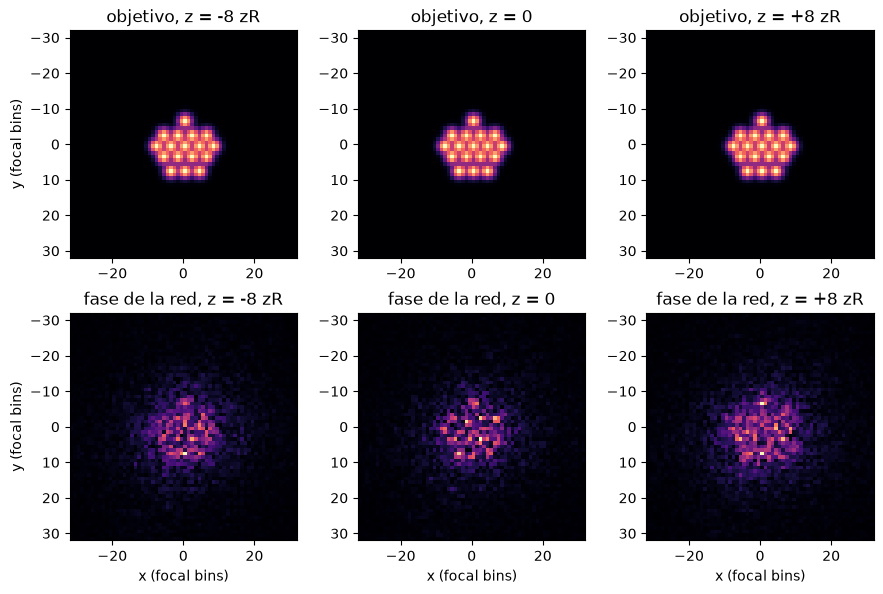

In [8]:
# los tres planos de la red bajo el objetivo, en raíz cuadrada para ver la luz débil alrededor de los puntos
net_images = plane_images(net.phi)
fig, axes = plt.subplots(2, 3, figsize=(9, 6))
for k, z in enumerate(DEPTHS):
    axes[0, k].imshow(amps[k, 32:96, 32:96], cmap="magma", extent=(-32, 32, 32, -32))
    axes[1, k].imshow(np.sqrt(net_images[k, 32:96, 32:96]), cmap="magma", extent=(-32, 32, 32, -32))
    axes[0, k].set_title(f"objetivo, z = {z}")
    axes[1, k].set_title(f"fase de la red, z = {z}")
    axes[1, k].set_xlabel("x (focal bins)")
axes[0, 0].set_ylabel("y (focal bins)")
axes[1, 0].set_ylabel("y (focal bins)")
fig.tight_layout()
plt.show()

La fila superior es el objetivo; la inferior es la luz que hace la fase de la red en las mismas tres profundidades, dibujada como amplitud para que se vea la luz débil. El retículo se reconoce en cada panel, pero los puntos de la red difieren en brillo y un halo de moteado alrededor se lleva parte de la potencia. La figura muestra que la red no hace una copia limpia; no muestra cuánto mejoraría otro método, y tampoco muestra las intensidades de las trampas, que son el fin de un arreglo de trampas. Ambas preguntas necesitan la línea base, de modo que la figura siguiente pone la exactitud del lazo clásico, iteración por iteración, contra el valor único de la red.

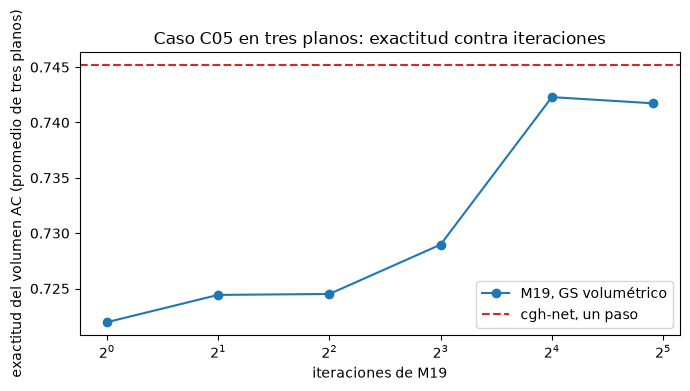

In [9]:
# la exactitud de M19 contra su número de iteraciones, con el paso único de la red como línea plana
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(marks, [ac_m19[k] for k in marks], "o-", label="M19, GS volumétrico")
ax.axhline(ac_net, color="C3", linestyle="--", label="cgh-net, un paso")
ax.set_xscale("log", base=2)
ax.set_xlabel("iteraciones de M19")
ax.set_ylabel("exactitud del volumen AC (promedio de tres planos)")
ax.set_title("Caso C05 en tres planos: exactitud contra iteraciones")
ax.legend()
fig.tight_layout()
plt.show()

La línea discontinua es la red, 0,7452, y los puntos son M19 con 1, 2, 4, 8, 16 y 30 iteraciones: 0,7220, 0,7244, 0,7245, 0,7290, 0,7423 y 0,7417. El eje abarca solo 0,025, de modo que las diferencias son pequeñas en términos absolutos, y el lazo no alcanza a la red en 30 iteraciones sobre este objetivo. M19 gana más entre 8 y 16 iteraciones y luego se detiene, que es la meseta de un algoritmo que no optimiza esta medida. En este retículo ningún número de iteraciones hasta 30 le da al lazo la exactitud de la red, y el paso de la red cuesta menos que una iteración. El híbrido del producto toma la fase de la red como inicio de M19; la celda siguiente lo ejecuta con 1, 3 y 7 iteraciones extra y le pregunta si el refinamiento ayudó.

In [10]:
# el híbrido del producto: la red y luego k iteraciones de M19 desde su fase, que se conservan solo si la exactitud sube
for k in (1, 3, 7):
    hyb = m17_cgh_net.run(setup, target, budget=Budget(k), rng=Rng(1))
    ac_h = evaluation.plane_accuracy(amps, hyb.phi, setup)
    print(f"red + {k} iteraciones de M19: refinamiento conservado {hyb.meta['refine_kept']}, AC {ac_h:.4f}")
refined = m19_multiplane.run(setup, target, budget=Budget(7), rng=Rng(1), init=net.phi, dz_m=dz)
print(f"la fase refinada, mostrada igual: AC {evaluation.plane_accuracy(amps, refined.phi, setup):.4f}")

red + 1 iteraciones de M19: refinamiento conservado False, AC 0.7452
red + 3 iteraciones de M19: refinamiento conservado False, AC 0.7452
red + 7 iteraciones de M19: refinamiento conservado False, AC 0.7452
la fase refinada, mostrada igual: AC 0.7272


El híbrido rechaza el refinamiento todas las veces: `refine_kept` es False con 1, 3 y 7 iteraciones extra y la exactitud devuelta es la de la red sola, 0,7452. La última línea muestra por qué. La fase refinada, que el módulo descartó, puntúa 0,7272, menos que la fase de la que partió. M19 ajusta el campo en los vóxeles que se le dan y al hacerlo degrada las imágenes que compara $AC$, de modo que el mejor inicio es un peor holograma según la medida que lo creó. La salvaguarda del producto es la comparación dentro del método, y llamar al método con `refine=False` devuelve la red sola. La exactitud es una vista del holograma. La otra es el arreglo de trampas mismo: cuánta luz reciben las trampas y cuán parecidas son. La celda siguiente puntúa cuatro hologramas con el modelo de trampa puntual del motor a la profundidad propia de las 51 trampas.

In [11]:
# la vista de las trampas: eficiencia y uniformidad de las 51 trampas puntuales a su profundidad, para cuatro hologramas
def trap_numbers(phi, st, traps):
    i = metrics.trap_intensities(forward.point_trap_fields(phi, st, traps), traps.weight)
    return metrics.efficiency(i), metrics.uniformity(i), metrics.rel_std(i)


holograms = {"cgh-net": net.phi, "M19 x 8": phis[8], "M19 x 30": phis[30], "red + M19 x 7": refined.phi}
numbers = {name: trap_numbers(phi, setup, target.traps) for name, phi in holograms.items()}
for name, (eff, uni, sigma) in numbers.items():
    print(f"{name:14s} eficiencia {eff:.3f}  uniformidad {uni:.3f}  desv. est. relativa {sigma:5.1f} %")

cgh-net        eficiencia 0.421  uniformidad 0.016  desv. est. relativa  75.5 %
M19 x 8        eficiencia 0.780  uniformidad 0.120  desv. est. relativa  49.4 %
M19 x 30       eficiencia 0.838  uniformidad 0.164  desv. est. relativa  37.7 %
red + M19 x 7  eficiencia 0.785  uniformidad 0.042  desv. est. relativa  51.3 %


Los números discrepan de la exactitud. La red pone 0,421 de la potencia de entrada en las trampas, contra 0,780 de M19 con 8 iteraciones y 0,838 con 30, y su uniformidad es 0,016, contra 0,120 y 0,164, con una desviación estándar relativa de 75,5 por ciento contra 49,4 y 37,7. Ninguno de los métodos iguala bien las trampas con este presupuesto, pero el lazo clásico les manda casi el doble de luz. El híbrido refinado queda en medio, con eficiencia 0,785 y uniformidad 0,042, de modo que el refinamiento de M19 sobre la fase de la red recupera eficiencia y pierde exactitud, que es el mismo intercambio visto del otro lado. La figura siguiente dibuja la eficiencia y la uniformidad de los cuatro hologramas.

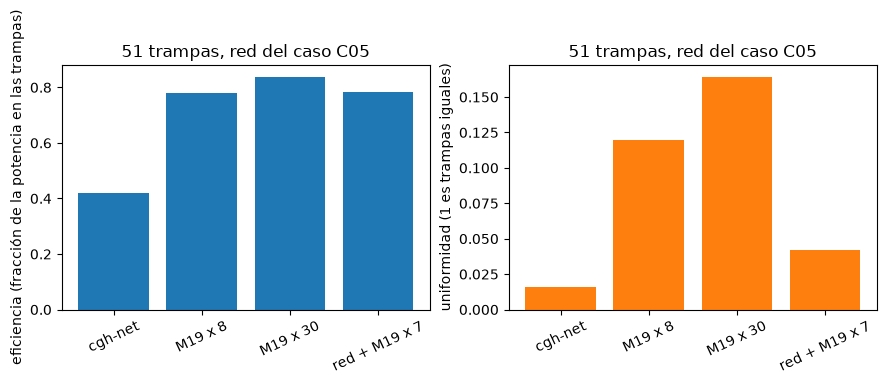

In [12]:
# los mismos números como barras: cuánta luz llega a las trampas y cuán parejas son
names = list(numbers)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
axes[0].bar(names, [numbers[n][0] for n in names], color="C0")
axes[0].set_ylabel("eficiencia (fracción de la potencia en las trampas)")
axes[1].bar(names, [numbers[n][1] for n in names], color="C1")
axes[1].set_ylabel("uniformidad (1 es trampas iguales)")
for ax in axes:
    ax.set_title("51 trampas, red del caso C05")
    ax.tick_params(axis="x", labelrotation=25)
fig.tight_layout()
plt.show()

Las barras repiten la tabla: la red es la más baja en ambos paneles, y M19 con 30 iteraciones la más alta. La figura muestra el intercambio en un solo objetivo y no dice si se mantiene en otros, pues un retículo repetido en tres planos es un caso favorable e inusual para M19. Ocho volúmenes más lo ponen a prueba, generados por el generador del producto con semilla fija: dos de cada tipo entre conjuntos aleatorios, retículos, anillos y volúmenes mixtos, de 9 a 90 trampas. Para cada uno la celda ejecuta la red, M19 con 4 y luego 8 iteraciones, el híbrido de 7 iteraciones y los números de trampa de la red y de M19 con 8.

In [13]:
# ocho volúmenes generados con la óptica de la evaluación reservada: la red, M19 con 4 y 8 iteraciones y el híbrido de 7
bench = evaluation.SETUP128
dz_b = m17_cgh_net.plane_dz_m(bench)
rng = np.random.default_rng(20261028)
rows = []
for kind in ("random", "lattice", "ring", "mixed") * 2:
    a, pts = generators.sample_volume(rng, kind)
    tgt = evaluation.volume_target(pts)
    net_v = m17_cgh_net.run(bench, tgt, budget=Budget(1), rng=Rng(1), refine=False)
    first = m19_multiplane.run(bench, tgt, budget=Budget(4), rng=Rng(1), dz_m=dz_b)
    second = m19_multiplane.run(bench, tgt, budget=Budget(4), rng=Rng(1), init=first.phi, dz_m=dz_b)
    hybrid = m17_cgh_net.run(bench, tgt, budget=Budget(7), rng=Rng(1))
    eff_n, uni_n, _ = trap_numbers(net_v.phi, bench, tgt.traps)
    eff_m, uni_m, _ = trap_numbers(second.phi, bench, tgt.traps)
    rows.append({"kind": kind, "traps": len(pts), "kept": bool(hybrid.meta["refine_kept"]),
                 "net": evaluation.plane_accuracy(a, net_v.phi), "m19_4": evaluation.plane_accuracy(a, first.phi),
                 "m19_8": evaluation.plane_accuracy(a, second.phi), "hybrid": evaluation.plane_accuracy(a, hybrid.phi),
                 "eff_net": eff_n, "eff_m19": eff_m, "uni_net": uni_n, "uni_m19": uni_m})
    print(f"{kind:8s} {len(pts):3d} trampas  AC red {rows[-1]['net']:.3f}, M19 x 4 {rows[-1]['m19_4']:.3f}, "
          f"M19 x 8 {rows[-1]['m19_8']:.3f}, híbrido {rows[-1]['hybrid']:.3f}")

random    12 trampas  AC red 0.657, M19 x 4 0.594, M19 x 8 0.595, híbrido 0.657
lattice   12 trampas  AC red 0.678, M19 x 4 0.590, M19 x 8 0.589, híbrido 0.678
ring      75 trampas  AC red 0.708, M19 x 4 0.603, M19 x 8 0.602, híbrido 0.708
mixed     90 trampas  AC red 0.678, M19 x 4 0.594, M19 x 8 0.594, híbrido 0.678
random    75 trampas  AC red 0.683, M19 x 4 0.592, M19 x 8 0.593, híbrido 0.683
lattice   48 trampas  AC red 0.693, M19 x 4 0.617, M19 x 8 0.619, híbrido 0.693
ring       9 trampas  AC red 0.656, M19 x 4 0.593, M19 x 8 0.594, híbrido 0.656
mixed      9 trampas  AC red 0.671, M19 x 4 0.593, M19 x 8 0.594, híbrido 0.671


La red queda sobre M19 en cada fila, por 0,06 a 0,11 de exactitud; la exactitud de M19 casi no se mueve entre 4 y 8 iteraciones, y el híbrido iguala a la red en cada fila, lo que significa que el refinamiento se descartó siempre. La figura siguiente dibuja las cuatro exactitudes de cada volumen.

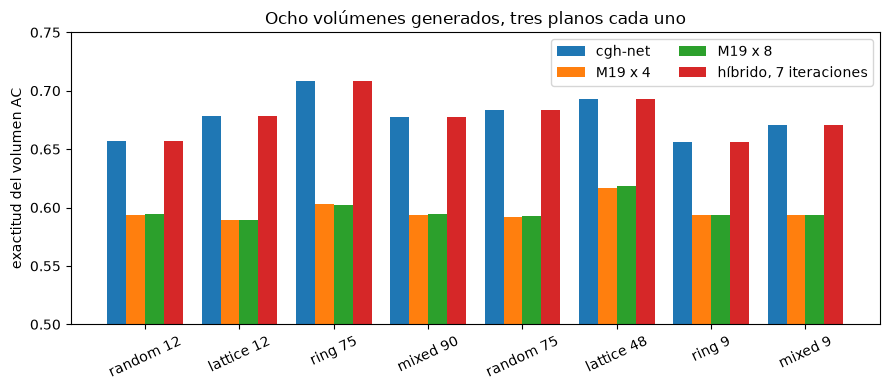

In [14]:
# la exactitud de los cuatro hologramas en cada uno de los ocho volúmenes
labels = [f"{r['kind']} {r['traps']}" for r in rows]
x = np.arange(len(rows))
fig, ax = plt.subplots(figsize=(9, 4))
series = (("net", "cgh-net"), ("m19_4", "M19 x 4"), ("m19_8", "M19 x 8"), ("hybrid", "híbrido, 7 iteraciones"))
for j, (key, name) in enumerate(series):
    ax.bar(x + 0.2 * (j - 1.5), [r[key] for r in rows], width=0.2, label=name)
ax.set_xticks(x, labels, rotation=25)
ax.set_ylim(0.5, 0.75)
ax.set_ylabel("exactitud del volumen AC")
ax.set_title("Ocho volúmenes generados, tres planos cada uno")
ax.legend(ncol=2)
fig.tight_layout()
plt.show()

Las barras rojas del híbrido tienen la misma altura que las de la red, y las barras de la red están sobre las dos barras de M19 en cada grupo. El eje vertical parte en 0,5 para que se vean las diferencias, de modo que las barras exageran la razón; la tabla de arriba tiene la razón verdadera. La figura muestra una ventaja constante en exactitud entre tipos de volumen y números de trampas, y no da información sobre las intensidades de las trampas, que la celda siguiente resume con las razones, el número de refinamientos conservados y las medianas de las trampas.

In [15]:
# las razones que pide la pregunta y cuántas veces el híbrido conserva el refinamiento
ratio_4 = np.array([r["net"] / r["m19_4"] for r in rows])
ratio_8 = np.array([r["net"] / r["m19_8"] for r in rows])
print(f"red / M19 con 4 iteraciones: mediana {np.median(ratio_4):.3f}, mínima {ratio_4.min():.3f}")
print(f"red / M19 con 8 iteraciones: mediana {np.median(ratio_8):.3f}, mínima {ratio_8.min():.3f}")
print(f"volúmenes donde la red supera a M19 con 8 iteraciones: {int(np.sum(ratio_8 > 1))} de {len(rows)}")
print(f"refinamientos conservados por el híbrido de 7 iteraciones: {sum(r['kept'] for r in rows)} de {len(rows)}")
print(f"eficiencia de las trampas, mediana: red {np.median([r['eff_net'] for r in rows]):.3f}, "
      f"M19 x 8 {np.median([r['eff_m19'] for r in rows]):.3f}")
print(f"uniformidad de las trampas, mediana: red {np.median([r['uni_net'] for r in rows]):.3f}, "
      f"M19 x 8 {np.median([r['uni_m19'] for r in rows]):.3f}")

red / M19 con 4 iteraciones: mediana 1.136, mínima 1.105
red / M19 con 8 iteraciones: mediana 1.135, mínima 1.105
volúmenes donde la red supera a M19 con 8 iteraciones: 8 de 8
refinamientos conservados por el híbrido de 7 iteraciones: 0 de 8
eficiencia de las trampas, mediana: red 0.390, M19 x 8 0.716
uniformidad de las trampas, mediana: red 0.575, M19 x 8 0.717


Los volúmenes de arriba son la muestra propia de este notebook. El registro del producto con datos reservados es mayor: la etapa de evaluación puntuó el grafo publicado en 162 volúmenes escritos antes del entrenamiento, frente a M19 con el mismo tiempo de reloj, y escribió el resultado en `data/derived/models/metrics.json`. La celda lo lee.

In [16]:
# el registro del espacio con datos reservados: 162 volúmenes, el híbrido frente a M19 con el mismo tiempo de reloj
metrics_doc = json.loads((ROOT / "data" / "derived" / "models" / "metrics.json").read_text(encoding="utf-8"))
slot = metrics_doc["slots"]["cgh-net"]
ratio = slot["accuracy_vs_gs"]
print(f"volúmenes reservados: {slot['held_out_n']}, línea base: {slot['baseline']}")
print(f"exactitud sobre la línea base: mediana {ratio['median']:.3f}, cuartiles {ratio['q1']:.3f} a {ratio['q3']:.3f}")


volúmenes reservados: 162, línea base: M19
exactitud sobre la línea base: mediana 1.140, cuartiles 1.102 a 1.160


## Resultados

**Respuesta:** Sí por la exactitud del volumen, no por los números de las trampas. En el caso C05 el paso único de la red puntúa una exactitud de 0,7452, sobre M19 con cualquier número de iteraciones hasta 30 (0,7417), a un costo menor que una iteración de M19. En los ocho volúmenes generados la red queda sobre M19 con 8 iteraciones en 8 de 8, con una razón mediana de 1,135 (mínima 1,105) bajo la misma cota de costo, coherente con la mediana de 1,140 que registra la evaluación del producto sobre 162 volúmenes a igual tiempo de reloj. El mismo holograma da a las trampas una eficiencia mediana de 0,390 contra 0,716 de M19 con 8 iteraciones, y 0,421 contra 0,838 en C05 con 30 iteraciones. La red no es un mejor inicio para M19: el híbrido conservó el refinamiento en 0 de 8 volúmenes y en ninguno de los tres presupuestos de C05, porque el refinamiento baja la exactitud que la red se entrenó para subir.

Lo que el notebook no muestra: cómo cambia el resultado con una métrica que premie trampas iguales (la evaluación del producto puntúa solo $AC$), cómo se comporta con un volumen que no está en los tres planos entrenados (el método rechaza ese objetivo con un error) y cómo se compara con un lazo que optimice $AC$ en vez de los vóxeles. La ventaja de DeepCGH que informa el artículo se reproduce entonces en dirección sobre la medida propia del artículo y no se traslada a la calidad con que se juzgan los arreglos de trampas.

## Resumen

Un holograma de tres planos puede juzgarse por las imágenes que hace o por las trampas que alimenta, y los dos juicios pueden ordenar los mismos dos hologramas en sentido opuesto. La red publicada da la mayor exactitud de imagen por menos que el costo de una iteración del lazo volumétrico, en el retículo del caso C05 y en ocho volúmenes generados. El lazo clásico da más luz a las trampas y las iguala mejor, porque las optimiza. El híbrido que ofrece el método conserva la fase de la red y descarta el refinamiento de M19, de modo que es la red sola. Quien quiera una vista previa rápida de un volumen, o un inicio cuyas imágenes sean correctas, tiene un uso para la red; quien necesite trampas de igual profundidad necesita un método que mire las trampas. El notebook siguiente del tema hace la misma pregunta para el otro método aprendido del producto, cuya red predice fases de trampas y fue rechazada.

## Referencias

- Eybposh, Caira, Atisa, Chakravarthula y Pégard, "DeepCGH: 3D computer-generated holography using deep learning", Optics Express 28, 26636 (2020), https://doi.org/10.1364/OE.399624.
- Whyte y Courtial, "Experimental demonstration of holographic three-dimensional light shaping using a Gerchberg-Saxton algorithm", New Journal of Physics 7, 117 (2005), https://doi.org/10.1088/1367-2630/7/1/117.
- Di Leonardo, Ianni y Ruocco, "Computer generation of optimal holograms for optical trap arrays", Optics Express 15, 1913 (2007), https://doi.org/10.1364/OE.15.001913.
- La ficha del modelo del producto `models/cgh-net.json` y el registro de evaluación `data/derived/models/metrics.json` (la cifra de 162 volúmenes citada en los Resultados).